# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [10]:
print(tx.columns.tolist())
CAT  = next(c for c in tx.columns if "categ" in c.lower())   # merchant category column
CUST = next(c for c in tx.columns if "cust" in c.lower())    # customer column
print("category column:", CAT, "| customer column:", CUST)

['txn_id', 'timestamp', 'day', 'hour', 'customer_id', 'city', 'merchant_category', 'amount_inr', 'distance_from_home_km', 'detector_score', 'is_fraud', 'night', 'label']
category column: merchant_category | customer column: customer_id


In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

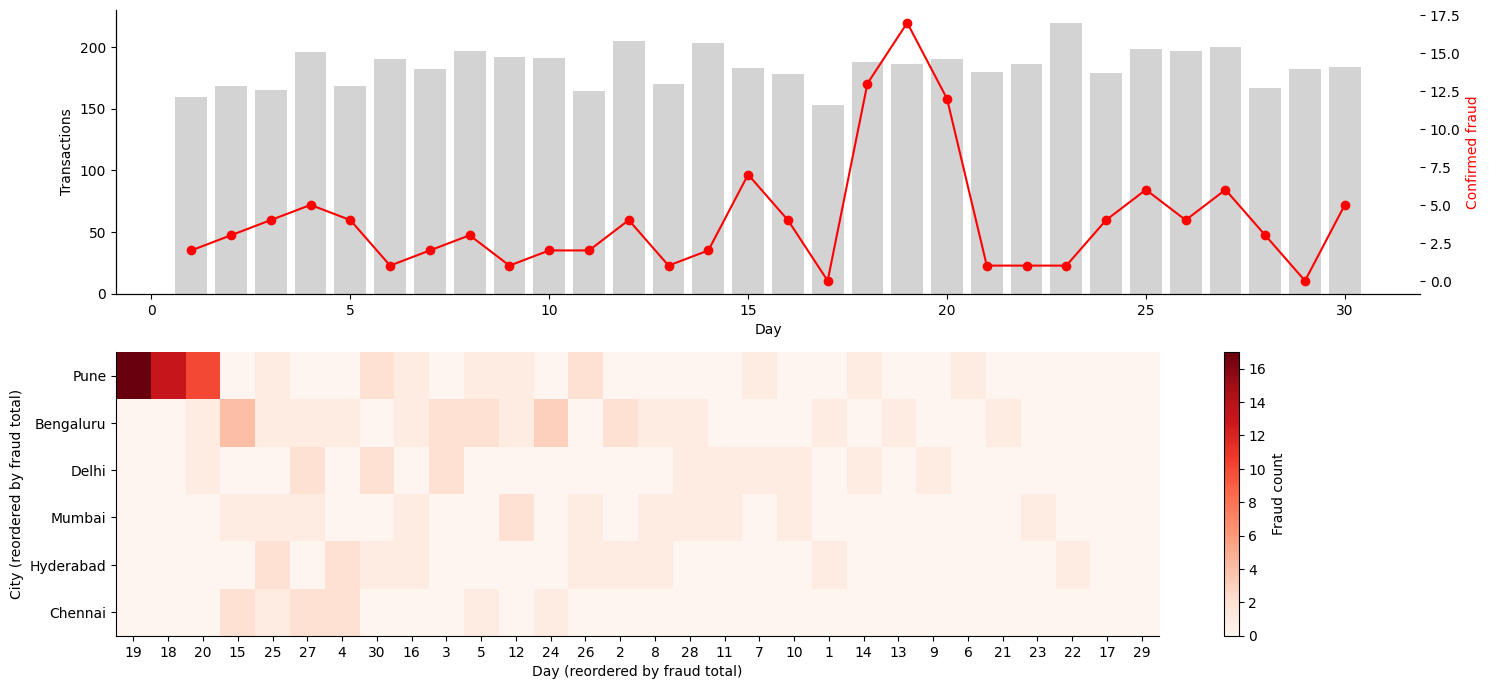

city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [12]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: daily counts (bars) + daily fraud (line, second axis)
daily_n = tx.groupby("day").size()
daily_f = tx.groupby("day").is_fraud.sum()
axes[0].bar(daily_n.index, daily_n.values, color="lightgrey")
axes[0].set_xlabel("Day"); axes[0].set_ylabel("Transactions")
ax2 = axes[0].twinx()
ax2.plot(daily_f.index, daily_f.values, "o-", color="red")
ax2.set_ylabel("Confirmed fraud", color="red")

# TODO 2: city x day fraud counts, rows and columns reordered by totals
heat = (tx[tx.is_fraud == 1]
        .pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
        .reindex(columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_xticks(range(heat.shape[1])); axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(heat.shape[0])); axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("Day (reordered by fraud total)"); axes[1].set_ylabel("City (reordered by fraud total)")
plt.colorbar(im, ax=axes[1], label="Fraud count")

plt.tight_layout(); plt.show()

# TODO 3: hottest (city, day) cells
print(heat.stack().sort_values(ascending=False).head(5))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The overview showed a concentration of fraud in one city over a few days, which a list of alerts sorted by score wouldn’t show. An alert list ranks single transactions, so a cluster of moderate-score fraud is invisible. In lecture terms, this is reordering the matrix so patterns pop out (Slide 39), and it is also the “overview first” step (Slide 30)

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

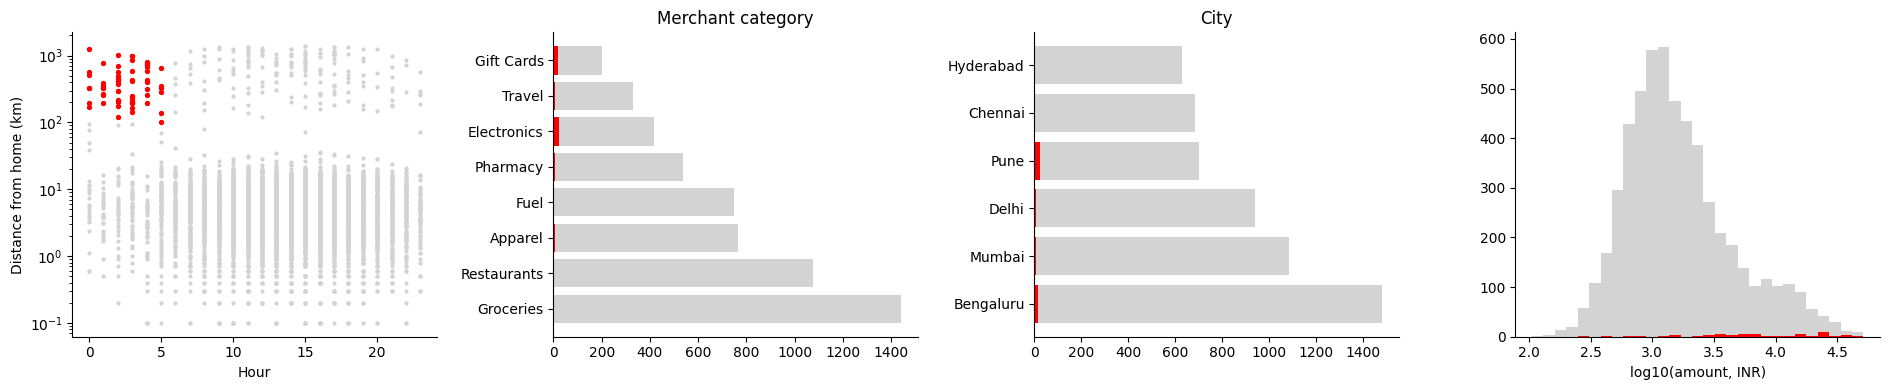

Brushed: 61
Fraud rate inside brush: 86.9% | overall: 2.2%
Share of ALL fraud captured by the brush: 44.2%


In [13]:
# TODO 1
brush = tx.night & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# (a) hour vs distance, log y
dist = tx.distance_from_home_km.clip(lower=0.1)
axes[0].scatter(tx.hour, dist, s=4, c="lightgrey")
axes[0].scatter(tx.hour[brush], dist[brush], s=8, c="red")
axes[0].set_yscale("log"); axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Distance from home (km)")

# (b) merchant category counts
allc = tx[CAT].value_counts()
brc = tx.loc[brush, CAT].value_counts().reindex(allc.index, fill_value=0)
axes[1].barh(allc.index, allc.values, color="lightgrey"); axes[1].barh(brc.index, brc.values, color="red")
axes[1].set_title("Merchant category")

# (c) city counts
allc = tx.city.value_counts()
brc = tx.loc[brush, "city"].value_counts().reindex(allc.index, fill_value=0)
axes[2].barh(allc.index, allc.values, color="lightgrey"); axes[2].barh(brc.index, brc.values, color="red")
axes[2].set_title("City")

# (d) log10 amount histogram
bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color="lightgrey")
axes[3].hist(np.log10(tx.loc[brush, "amount_inr"]), bins=bins, color="red")
axes[3].set_xlabel("log10(amount, INR)")

plt.tight_layout(); plt.show()

# TODO 3
print(f"Brushed: {brush.sum():,}")
print(f"Fraud rate inside brush: {tx.loc[brush, 'is_fraud'].mean():.1%} | overall: {tx.is_fraud.mean():.1%}")
print(f"Share of ALL fraud captured by the brush: {tx.loc[brush, 'is_fraud'].sum() / tx.is_fraud.sum():.1%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The brush’s fraud rate is very high, but it probably captures only a small share of all fraud. So the rule has high precision and low recall: relying on it alone would miss most fraud. The city view (c) hints at where the rest is, since the fraud sits in a particular city that the brush doesn’t isolate. Check your output to confirm

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [14]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: best of 5 runs
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (per_item_us * 1e-6)           # rows filterable in 0.1 s

# TODO 3
t_50m = per_item_us * 1e-6 * 50_000_000
skip_pct = max(0, 1 - 0.1 / t_50m) * 100        # % of rows that must be skipped

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 14.1 ms -> 0.0141 us/row -> max 7,111,340 rows in 0.1 s
50M rows -> 0.70 s; must skip 85.8% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
Sampling (or pre-aggregation / binning) is a reduce technique: the slider filters a small sample or pre-aggregated counts, so it stays instant. The analyst loses detail and exactness. Rare fraud cases may be missing from the sample, and counts are approximate until the full query runs.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,f1
0,0.05,2012,114,1898,6,0.056660,0.950000,0.106942
1,0.10,1167,111,1056,9,0.095116,0.925000,0.172494
2,0.15,786,110,676,10,0.139949,0.916667,0.242826
3,0.20,596,106,490,14,0.177852,0.883333,0.296089
4,0.25,471,105,366,15,0.222930,0.875000,0.355330
5,0.30,401,104,297,16,0.259352,0.866667,0.399232
6,0.35,355,104,251,16,0.292958,0.866667,0.437895
7,0.40,319,104,215,16,0.326019,0.866667,0.473804
8,0.45,283,104,179,16,0.367491,0.866667,0.516129
9,0.50,260,101,159,19,0.388462,0.841667,0.531579


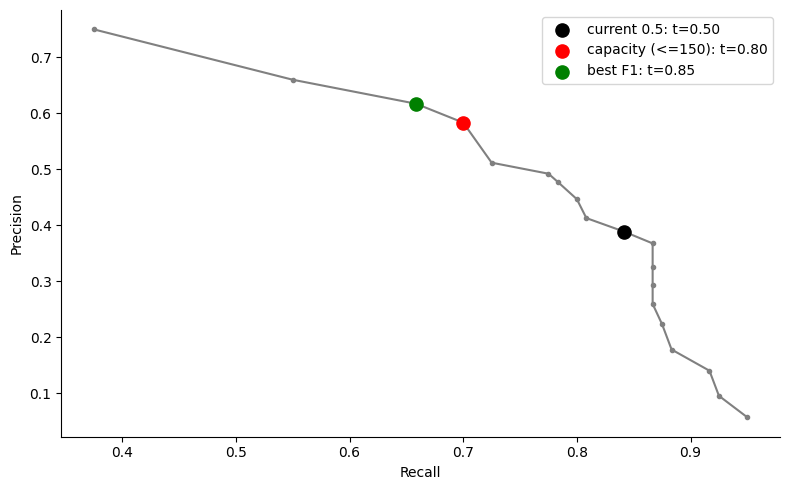

Recommend threshold 0.80: 144 alerts/month (within the 150 capacity), recall 70%, precision 58%. Best F1 is at 0.85 with 128 alerts.


In [15]:
rows = []
total_fraud = int(tx.is_fraud.sum())
for th in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flagged = tx.detector_score >= th
    alerts = int(flagged.sum())
    tp = int((flagged & (tx.is_fraud == 1)).sum())
    fp = alerts - tp
    fn = total_fraud - tp
    precision = tp / alerts if alerts else np.nan
    recall = tp / total_fraud
    f1 = 2 * precision * recall / (precision + recall) if alerts and (precision + recall) > 0 else 0.0
    rows.append(dict(threshold=th, alerts=alerts, TP=tp, FP=fp, FN=fn, precision=precision, recall=recall, f1=f1))
pr = pd.DataFrame(rows)
display(pr)

# TODO 2
capacity_choice = pr.loc[pr[pr.alerts <= 150].recall.idxmax()]
best_f1 = pr.loc[pr.f1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", ms=3, color="grey")
for r, name, col in [(current, "current 0.5", "black"), (capacity_choice, "capacity (<=150)", "red"), (best_f1, "best F1", "green")]:
    ax.scatter(r.recall, r.precision, s=90, color=col, label=f"{name}: t={r.threshold:.2f}", zorder=3)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommend threshold {capacity_choice.threshold:.2f}: {int(capacity_choice.alerts)} alerts/month "
      f"(within the 150 capacity), recall {capacity_choice.recall:.0%}, precision {capacity_choice.precision:.0%}. "
      f"Best F1 is at {best_f1.threshold:.2f} with {int(best_f1.alerts)} alerts.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops should make the call. The model optimises a statistic (F1), but the real constraints are investigator capacity and the cost of a missed fraud versus a wasted review, which the model can’t know. Visual analytics keeps a human in the loop (Slides 35–37), because steering a parameter by seeing the precision–recall trade-off is a judgment about business cost, not only a number.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [16]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3]
fig1 = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
                  hover_name="txn_id",
                  hover_data={CUST: True, "city": True, CAT: True,
                              "distance_from_home_km": ":.0f", "detector_score": ":.2f"})
fig1.update_layout(dragmode="select", title="Flagged transactions (score >= 0.3): select to inspect")
fig1.show()

# TODO 2: drill-down sunburst, city -> category, coloured by fraud rate
g = (tx.groupby(["city", CAT])
       .agg(n=("is_fraud", "size"), fraud_rate=("is_fraud", "mean")).reset_index())
fig2 = px.sunburst(g, path=["city", CAT], values="n", color="fraud_rate",
                   color_continuous_scale="Reds", title="City → merchant category (colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips show one case at a time, so for 400 flagged cases the investigator would have to hover 400 times and keep everything in working memory, with no overview. The city × day heatmap (Task 1) or the linked views (Task 2) fix this: they show the whole distribution at once.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Inside window: nan% | outside: 2.2% | chi-square p = 1.00e+00
(a) same city, other days: nan% | (b) other cities, same days: nan% | rest: 2.2%


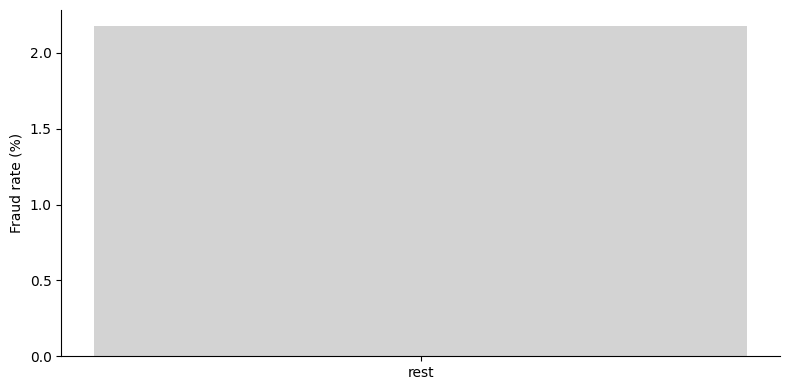

Verdict: NOT SUPPORTED. A counter-example is also elevated, so the effect is not specific to this city-day window.


In [17]:
from scipy.stats import chi2_contingency

HOT_CITY = "FILL_ME"        # top city from Task 1
DAY_LO, DAY_HI = 0, 0       # day range from Task 1

# TODO 1
in_city = tx.city == HOT_CITY
in_days = tx.day.between(DAY_LO, DAY_HI)
in_window = in_city & in_days

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p, _, _ = chi2_contingency(ct)
rate_in = tx.loc[in_window, "is_fraud"].mean()
rate_out = tx.loc[~in_window, "is_fraud"].mean()
print(f"Inside window: {rate_in:.1%} | outside: {rate_out:.1%} | chi-square p = {p:.2e}")

# TODO 3: counter-example searches
same_city_other_days = tx[in_city & ~in_days].is_fraud.mean()
other_cities_same_days = tx[~in_city & in_days].is_fraud.mean()
rest = tx[~in_city & ~in_days].is_fraud.mean()
print(f"(a) same city, other days: {same_city_other_days:.1%} | (b) other cities, same days: {other_cities_same_days:.1%} | rest: {rest:.1%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
labels_ = ["window", "same city,\nother days", "other cities,\nsame days", "rest"]
vals = [rate_in, same_city_other_days, other_cities_same_days, rest]
ax.bar(labels_, [v * 100 for v in vals], color=["red", "lightgrey", "lightgrey", "lightgrey"])
ax.set_ylabel("Fraud rate (%)")
plt.tight_layout(); plt.show()

# TODO 5
if p < 0.01 and rate_in > 3 * max(same_city_other_days, other_cities_same_days, rest):
    print("Verdict: SUPPORTED. Fraud is concentrated in this city AND these days; neither counter-example explains it. "
          "Consistent with a localized ring, but shared cards/merchants/devices must confirm it.")
else:
    print("Verdict: NOT SUPPORTED. A counter-example is also elevated, so the effect is not specific to this city-day window.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

Either counter-example could have killed the hypothesis, in different ways. (a) If the same city had high fraud on other days, it would suggest the city is persistently risky (for example a weak merchant or a particular location), not a time-limited ring. (b) If other cities were also high on the same days, it would point to a system-wide event (a data breach, a detector fault, or a promotion), not a city-specific ring

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month PayKart had [N] transactions with [F] confirmed fraud, concentrated in [city] on days [X–Y], where the fraud rate was [rate_in] against [rate_rest] elsewhere. I recommend setting the threshold to [capacity_choice.threshold], which gives [alerts] alerts/month (within the 150 capacity) with recall [recall] and precision [precision]. This is a decision for the Head of Fraud Ops, not the model, so the human stays in the loop and can move it as capacity changes. The first interactive view to build is the city × day overview with linked brushing, because overview-first shows the concentration immediately and avoids the 0.1 s dynamic-query problem on 50M rows by working on aggregates. The “night-time, far-from-home” rule has high precision but captures only [share] of fraud, so it shouldn’t be used alone. The feedback loop (Slide 51) to add: investigators’ confirmed labels flow back into retraining the detector each month.